# 01 · Exploración de datos y primeras corridas (Hito 2)

Albert-sim · José David Quiñonez Rehenals (T00083600). Semilla principal: 42.

Este notebook solo **explora**: las cifras oficiales salen de `python -m src.run_experimentos` (carpeta `experiments/`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.run_experimentos import cargar
convs, turnos = cargar(42)
convs.shape, turnos.shape

((2300, 11), (7837, 14))

## 1. Calibración con los agregados del piloto (31 días, 120 conversaciones)

In [2]:
g1 = convs[convs.variante=='G1']; tg1 = turnos[turnos.conversacion_id.isin(g1.conversacion_id)]
al_llm = (tg1.s_sin_atajo.astype(bool) & ~tg1.obs.isin(['PIDE_ASESOR','NEGATIVO'])).mean()
pd.DataFrame({'Piloto UPC':[36.0, 23.0], 'Sintético G1 (seed 42)':[100*g1.requiere_asesor.mean(), 100*al_llm]},
             index=['% conversaciones con asesor','% mensajes que caen al LLM']).round(1)

,Piloto UPC,Sintético G1 (seed 42)
% conversaciones con asesor,36.0,33.8
% mensajes que caen al LLM,23.0,23.2


## 2. Estadísticas descriptivas

In [3]:
desc = convs.groupby('particion').agg(conversaciones=('conversacion_id','count'), pct_requiere=('requiere_asesor', lambda s: round(100*s.mean(),1)),
       turnos_medios=('n_turnos','mean'), pct_tercero=('tipo_usuario', lambda s: round(100*(s=='tercero').mean(),1)),
       pct_mala_escritura=('escritura', lambda s: round(100*(s=='mala').mean(),1)), pct_con_voz=('usa_voz', lambda s: round(100*s.mean(),1)))
desc.round(2)

,conversaciones,pct_requiere,turnos_medios,pct_tercero,pct_mala_escritura,pct_con_voz
particion,,,,,,
test_g1,300,30.3,3.34,39.7,24.7,21.3
test_g2,300,32.3,3.47,42.3,34.3,25.0
train,1400,34.9,3.44,41.9,24.0,20.8
val,300,31.7,3.26,39.0,28.3,17.3


In [4]:
convs.groupby('intencion').requiere_asesor.agg(['count','mean']).sort_values('mean').round(2)

,count,mean
intencion,,
horarios,347,0.04
sedes,278,0.05
preparacion,235,0.13
resultados_envio,243,0.44
estado_estudio,776,0.47
otro,131,0.53
pagos,290,0.59


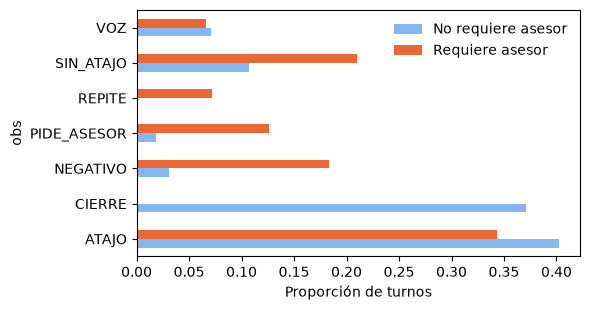

In [5]:
tab = pd.crosstab(turnos.obs, turnos.merge(convs[['conversacion_id','requiere_asesor']]).requiere_asesor, normalize='columns')
ax = tab.plot.barh(figsize=(6,3.2), color=['#86b6ef','#eb6834'])
ax.set_xlabel('Proporción de turnos'); ax.legend(['No requiere asesor','Requiere asesor'], frameon=False); plt.tight_layout()

## 3. Resultados de las líneas base (5 semillas)

In [6]:
print(open('../experiments/resumen.md').read())

# Resultados (media Â± desv. estÃ¡ndar, 5 semillas)

Semillas: 42, 43, 44, 45, 46. Umbrales de Ã©xito (Hito 1): {"recall": 0.9, "f1": 0.8, "pct_innecesarios": 20.0, "retraso_mediana": 1.0, "ece": 0.1, "brecha_f1_subgrupo": 0.1}

Ï„* = regla predeclarada (0,20; solo baja si en validaciÃ³n recall < 0,90). Â«Ï„ en validaciÃ³nÂ» = desvÃ­o justificado (mÃ¡x. F1 con recall â‰¥ 0,90 en validaciÃ³n). Los hiperparÃ¡metros (Î± del HMM, C de la logÃ­stica) se eligen solo en validaciÃ³n.

## Prueba independiente G2 (mÃ©trica principal)

| Modelo | recall | f1 | precision | pct_innecesarios | retraso_mediana | ece | brecha_f1_max |
|---|---|---|---|---|---|---|---|
| LÃ­nea base 1 Â· Reglas fijas (Albert) | 0.890 Â± 0.030 | 0.819 Â± 0.026 | 0.758 Â± 0.026 | 24.153 Â± 2.593 | 1.000 Â± 0.000 | â€” | 0.079 Â± 0.031 |
| LÃ­nea base 2 Â· Clase mayoritaria | 0.000 Â± 0.000 | 0.000 Â± 0.000 | 0.000 Â± 0.000 | 0.000 Â± 0.000 | â€” | 0.016 Â± 0.018 | 0.000 Â± 0.000 |
| (A) HMM Â· Ï„* predeclarado | 1.000 Â±

## 4. Exploración en **validación**: sensibilidad del HMM al umbral τ

Solo para orientar el Hito 3. La regla predeclarada fija τ* = 0,20 (costos C_FP = 1, C_FN = 4).

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
tau,0.050,0.100,0.150,0.200,0.250,0.300,0.350,0.400,0.450,0.500,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900,0.950
recall,1.000,1.000,1.000,1.000,0.979,0.979,0.979,0.968,0.968,0.958,0.958,0.958,0.926,0.926,0.905,0.895,0.832,0.768,0.684
precision,0.466,0.546,0.546,0.576,0.578,0.578,0.578,0.767,0.773,0.771,0.875,0.875,0.967,0.967,1.000,1.000,1.000,1.000,1.000
f1,0.635,0.706,0.706,0.731,0.727,0.727,0.727,0.856,0.860,0.854,0.915,0.915,0.946,0.946,0.950,0.944,0.908,0.869,0.813


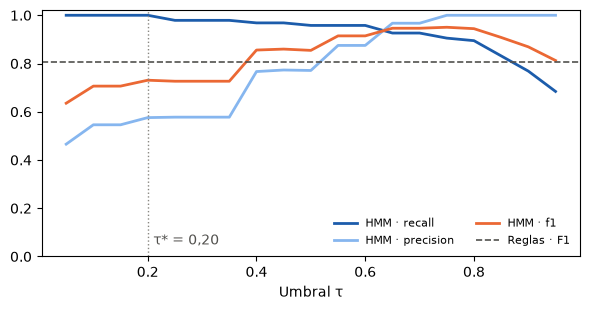

In [7]:
from src.modelos import HMMEscalamiento, ReglasFijas, aplicar
from src.metricas import evaluar
sub = lambda p: (convs[convs.particion==p], turnos[turnos.conversacion_id.isin(convs[convs.particion==p].conversacion_id)])
tr, va = sub('train'), sub('val')
hmm = HMMEscalamiento().ajustar(*tr)
filas = []
for tau in np.round(np.arange(0.05, 0.96, 0.05), 2):
    hmm.tau = tau; r = evaluar(aplicar(hmm, *va)); filas.append({'tau':tau, 'recall':r['recall'], 'precision':r['precision'], 'f1':r['f1']})
barrido = pd.DataFrame(filas); reglas = evaluar(aplicar(ReglasFijas(), *va))
barrido.to_csv('../experiments/exploracion_tau_validacion_seed42.csv', index=False)
fig, ax = plt.subplots(figsize=(6,3.2))
for k, c in [('recall','#1c5cab'),('precision','#86b6ef'),('f1','#eb6834')]: ax.plot(barrido.tau, barrido[k], color=c, lw=2, label=f'HMM · {k}')
ax.axhline(reglas['f1'], color='#52514e', ls='--', lw=1.2, label='Reglas · F1'); ax.axvline(0.20, color='#898781', ls=':', lw=1)
ax.text(0.21, 0.05, 'τ* = 0,20', color='#52514e'); ax.set_xlabel('Umbral τ'); ax.set_ylim(0,1.02); ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig('../experiments/fig_tau_validacion_seed42.png', dpi=200)
barrido.round(3).T

## 5. Primeros errores de las reglas (falsos negativos en validación)

In [8]:
res = aplicar(ReglasFijas(), *va)
fn = res[(res.requiere_asesor==1)&(res.escala==0)].head(5)
for cid in fn.conversacion_id:
    print('---', cid, convs.set_index('conversacion_id').loc[cid, ['intencion','tipo_usuario','escritura']].tolist())
    print(turnos[turnos.conversacion_id==cid][['turno','texto','obs']].to_string(index=False))

--- G1-42-00181 ['estado_estudio', 'tercero', 'mala']
 turno                                                    texto    obs
     1      Buenas tardes, consulto por el estudio de mi esposa  ATAJO
     2 Me dijeron que la muestra fue rechazda y no se que hacer  ATAJO
     3 Me dijeron que la muestra fue rechazda y no se que hacer REPITE
--- G1-42-00190 ['estado_estudio', 'tercero', 'mala']
 turno                                                              texto       obs
     1 Buenos días, quería saber si ya está lsito el resultado de mi papa     ATAJO
     2                                                                Mmm SIN_ATAJO
     3                                               ¿y también el sabado     ATAJO
     4                                                      [NOTA_DE_VOZ]       VOZ
     5            Me dijeron q la muestra fue rechazada y no se qué hacer     ATAJO
--- G1-42-00191 ['estado_estudio', 'titular', 'buena']
 turno                                  texto    

## 6. Regresión logística (B) vs. HMM (A) en la prueba independiente G2

Cifras de `experiments/resumen_cv5.csv` y `experiments/resumen.csv` (5 semillas). «τ*» = regla predeclarada; «τ en validación» = desvío justificado (máx. F1 con recall ≥ 0,90 en validación).

In [9]:
import pandas as pd
r = pd.read_csv('../experiments/resumen.csv', header=[0,1], index_col=[0,1]).loc['test_g2']
r.xs('mean', axis=1, level=1)[['recall','f1','precision','pct_innecesarios','retraso_mediana','ece','brecha_f1_max']].round(3)

,recall,f1,precision,pct_innecesarios,retraso_mediana,ece,brecha_f1_max
modelo,,,,,,,
Línea base 1 · Reglas fijas (Albert),0.890,0.819,0.758,24.153,1.0,NaN,0.079
Línea base 2 · Clase mayoritaria,0.000,0.000,0.000,0.000,NaN,0.016,0.000
(A) HMM · τ* predeclarado,1.000,0.708,0.548,45.183,0.0,0.120,0.119
(A') HMM · τ en validación,0.939,0.914,0.895,10.511,0.8,0.132,0.133
(B) Logística · τ* predeclarado,0.998,0.797,0.665,33.541,0.0,0.149,0.145
(B') Logística · τ en validación,0.982,0.919,0.863,13.737,0.0,0.112,0.160


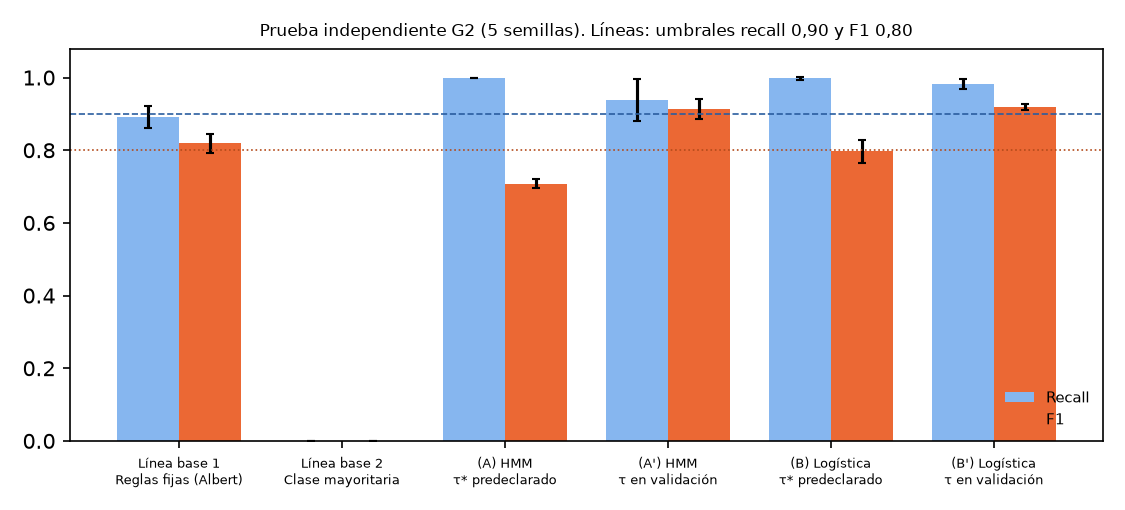

In [10]:
from IPython.display import Image
Image('../experiments/fig_comparacion_test_g2.png')

## 7. Validación cruzada de 5 particiones (G1, semilla 42)

In [11]:
cv = pd.read_csv('../experiments/cv5_seed42.csv')
cv.groupby('modelo', sort=False)[['recall','f1','precision','pct_innecesarios']].agg(['mean','std']).round(3)

recall            f1        precision  \
                                       mean    std   mean    std      mean   
modelo                                                                       
Línea base 1 · Reglas fijas (Albert)  0.875  0.029  0.815  0.028     0.764   
Línea base 2 · Clase mayoritaria      0.000  0.000  0.000  0.000     0.000   
(A) HMM · τ* predeclarado             1.000  0.000  0.738  0.028     0.586   
(A') HMM · τ en validación            0.928  0.011  0.949  0.006     0.972   
(B) Logística · τ* predeclarado       1.000  0.000  0.827  0.041     0.707   
(B') Logística · τ en validación      0.988  0.008  0.966  0.008     0.946   

                                            pct_innecesarios         
                                        std             mean    std  
modelo                                                               
Línea base 1 · Reglas fijas (Albert)  0.041           23.647  4.111  
Línea base 2 · Clase mayoritaria      0.000            0.000  0.000  
(A) HMM · τ* predeclarado             0.035           41.416  3.518  
(A') HMM · τ en validación            0.016            2.827  1.634  
(B) Logística · τ* predeclarado       0.061           29.346  6.127  
(B') Logística · τ en validación      0.014            5.423  1.432

## 8. Errores clasificados (≥ 10 casos) — hipótesis por validar

In [12]:
pd.read_csv('../experiments/errores_por_tipo.csv')

,modelo,error,tipo_error,casos
0,(A') HMM · τ en validación,FN,FN_conversacion_corta,1
1,(A') HMM · τ en validación,FN,FN_sin_senal_explicita,2
2,(A') HMM · τ en validación,FN,FN_voz,6
3,(A') HMM · τ en validación,FP,FP_lexico_negativo,1
4,(A') HMM · τ en validación,FP,FP_pide_asesor_sin_necesidad,2
5,(B') Logística · τ en validación,FN,FN_voz,3
6,(B') Logística · τ en validación,FP,FP_lexico_negativo,1
7,(B') Logística · τ en validación,FP,FP_pide_asesor_sin_necesidad,4
8,(B') Logística · τ en validación,FP,FP_sin_atajo_acumulado,4
9,(B') Logística · τ en validación,FP,FP_voz,5


In [13]:
m = pd.read_csv('../experiments/errores_muestra.csv')
pd.set_option('display.max_colwidth', 110)
m[['modelo','error','tipo_error','trayectoria','mensajes']].head(10)

,modelo,error,tipo_error,trayectoria,mensajes
0,(A') HMM · τ en validación,FN,FN_voz,VOZ > ATAJO > VOZ > NEGATIVO > VOZ,[NOTA_DE_VOZ] | ¿Cuánto se demora? | [NOTA_DE_VOZ] | Esto es inaceptable | [NOTA_DE_VOZ]
1,(A') HMM · τ en validación,FN,FN_sin_senal_explicita,SIN_ATAJO > SIN_ATAJO > SIN_ATAJO,Tengo un inconveniente con mi factura electrónica | Mis datos quedaron mal registrados | El NIT en la fact...
2,(A') HMM · τ en validación,FN,FN_voz,ATAJO > ATAJO > ATAJO > VOZ,El resultado de mi esposa nunca llegó | ¿Cuánto se demora? | El documento que llegó no es mío | [NOTA_DE_VOZ]
3,(A') HMM · τ en validación,FP,FP_pide_asesor_sin_necesidad,ATAJO > PIDE_ASESOR > VOZ > SIN_ATAJO > SIN_ATAJO,¿Hasta que hora atienden hoy? | ¿tengo q ir en persona | [NOTA_DE_VOZ] | Gracis | ¿y los domingos
4,(A') HMM · τ en validación,FN,FN_sin_senal_explicita,ATAJO > SIN_ATAJO > SIN_ATAJO,¿Por qué medio etregan los resultados? | el email registrado no es el mío | Esto es incaeptable
5,(A') HMM · τ en validación,FN,FN_conversacion_corta,ATAJO > ATAJO > PIDE_ASESOR,¿Se puede pagar por Nequi? | Pagué en línea y figura sin pagar | ¿Hay algún humano que me ayude?
6,(A') HMM · τ en validación,FN,FN_voz,ATAJO > SIN_ATAJO > SIN_ATAJO > VOZ,¿Ya publicaron mi resultado? | Dicen que hay que repetir la toma y nadie me explica | La página dice en pr...
7,(A') HMM · τ en validación,FN,FN_voz,ATAJO > ATAJO > VOZ,El resultado de mi hijo nnca llegó | El documento que lelgó no es mío | [NOTA_DE_VOZ]
8,(A') HMM · τ en validación,FN,FN_voz,ATAJO > SIN_ATAJO > VOZ,Necesito saber cómo va mi estudio | Dicen que hay que repetir la toma y nadie me explica | [NOTA_DE_VOZ]
9,(A') HMM · τ en validación,FP,FP_pide_asesor_sin_necesidad,SIN_ATAJO > PIDE_ASESOR > SIN_ATAJO > ATAJO > CIERRE,¿Hasta qué hoar atiendne hoy? | ¿Tengo que ir en persona? | Grcias | ¿Hay parqueadero? | vale gracias
